# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** ____________________________________  
**Група:** _____________________________________________  
**Дата:** ______________________________________________

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical
print("Імпорт успішний")

Імпорт успішний


### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не размили в полі?.."""
print(texts[:100])

Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розві


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [3]:
texts = texts.replace('\ufeff', '')
maxWordsCount = 1000
tokenizer = Tokenizer(
    num_words=maxWordsCount,
    filters='!"#$%&()*+,-–—./:;<=>?@[\\]^_`{|}~\t\n\r«»“”„…',
    lower=True,
    split=' ',
    char_level=False
)
tokenizer.fit_on_texts([texts])
print("Унікальних слів:", len(tokenizer.word_index))
print("Відповідностей у word_index:", len(tokenizer.word_index))

Унікальних слів: 35
Відповідностей у word_index: 35


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [4]:
res = np.array(tokenizer.texts_to_sequences([texts])[0])
inp_words = 3

X = np.array([res[i:i + inp_words] for i in range(len(res) - inp_words)])
Y = to_categorical(res[inp_words:], num_classes=maxWordsCount)

print("X:", X.shape, "Y:", Y.shape)
print("Перший приклад:", X[0], [tokenizer.index_word[i] for i in X[0]])
print("Цільове слово:", tokenizer.index_word[res[inp_words]])

X: (49, 3) Y: (49, 1000)
Перший приклад: [7 8 7] ['думи', 'мої', 'думи']
Цільове слово: мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [5]:
model = Sequential()
model.add(Embedding(maxWordsCount, 300, input_length=inp_words))
model.add(SimpleRNN(128, activation='tanh', return_sequences=True))
model.add(LSTM(128, activation='tanh'))
model.add(Dropout(0.2))
model.add(Dense(128, activation='relu'))
model.add(Dense(maxWordsCount, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [6]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.build(input_shape=(None, inp_words))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [7]:
history = model.fit(X, Y, batch_size=32, epochs=50)
print("Остання епоха: accuracy =", history.history['accuracy'][-1],
      ", loss =", history.history['loss'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.0000e+00 - loss: 6.9072
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.2245 - loss: 6.8930
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.4286 - loss: 6.8783 
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4898 - loss: 6.8563
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.3878 - loss: 6.8202
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3673 - loss: 6.7700
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2653 - loss: 6.6618
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1837 - loss: 6.4600 
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1633 - loss: 6.1011
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1224 - loss: 5.4452 
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.0816 - loss: 4.4257 
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.0408 - loss: 

### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

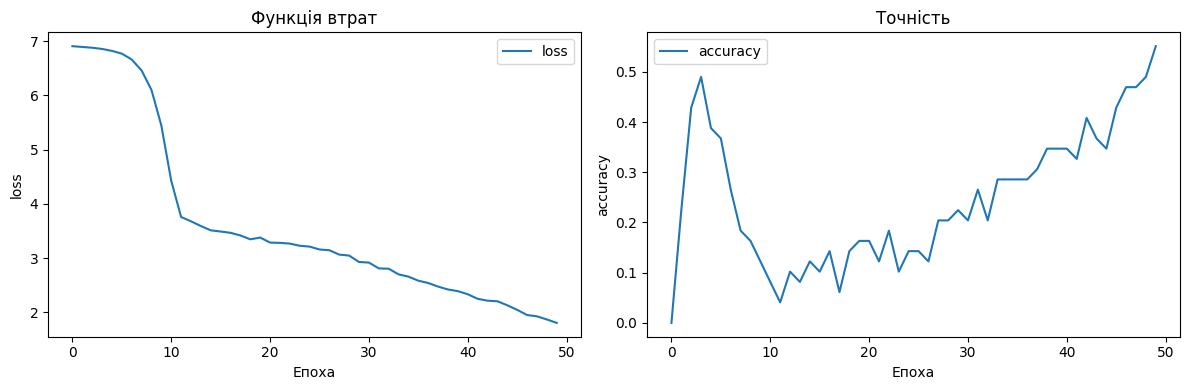

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['loss'])
ax[0].set_title('Функція втрат')
ax[0].set_xlabel('Епоха')
ax[0].set_ylabel('loss')
ax[0].legend(['loss'])

ax[1].plot(history.history['accuracy'])
ax[1].set_title('Точність')
ax[1].set_xlabel('Епоха')
ax[1].set_ylabel('accuracy')
ax[1].legend(['accuracy'])

plt.tight_layout()
plt.show()

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [9]:
def buildPhrase(texts, str_len=20):
    data = tokenizer.texts_to_sequences([texts])[0]
    # Обробка невідомих слів: вони відкидаються токенізатором,
    # тому перевіряємо, що лишилось щонайменше inp_words відомих слів
    if len(data) < inp_words:
        return f"Потрібно щонайменше {inp_words} відомих слова, знайдено {len(data)}"

    result = texts
    for _ in range(str_len):
        x = np.array(data[-inp_words:]).reshape(1, inp_words)
        pred = model.predict(x, verbose=0)
        idx = int(np.argmax(pred, axis=1)[0])
        data.append(idx)
        result += " " + tokenizer.index_word.get(idx, "")
    return result

print(buildPhrase("Думи мої думи", 20))

Думи мої думи лихо лихо лихо на на на чом чом вітер не не в винесли в не не в винесли в не


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [10]:
%pip install keras-tuner
import keras_tuner as kt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [11]:
def build_model(hp):
    model = Sequential()
    model.add(Embedding(
        maxWordsCount,
        hp.Int('embedding_dim', min_value=128, max_value=512, step=64),
        input_length=inp_words))
    model.add(SimpleRNN(
        hp.Int('rnn_units', min_value=64, max_value=256, step=64),
        activation='tanh', return_sequences=True))
    model.add(LSTM(
        hp.Int('lstm_units', min_value=64, max_value=256, step=64),
        activation='tanh'))
    model.add(Dropout(hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)))
    model.add(Dense(
        hp.Int('dense_units', min_value=64, max_value=256, step=64),
        activation='relu'))
    model.add(Dense(maxWordsCount, activation='softmax'))

    model.compile(
        optimizer=hp.Choice('optimizer', ['adam', 'rmsprop']),
        loss='categorical_crossentropy',
        metrics=['accuracy'])
    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [12]:
tuner = kt.RandomSearch(
    build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction')

tuner.search(X, Y, epochs=10, batch_size=32)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
for name in ['embedding_dim', 'rnn_units', 'lstm_units',
             'dropout_rate', 'dense_units', 'optimizer']:
    print(name, '=', best_hps.get(name))

Trial 10 Complete [00h 00m 04s]
accuracy: 0.3877550959587097

Best accuracy So Far: 0.6122449040412903
Total elapsed time: 00h 00m 41s
embedding_dim = 448
rnn_units = 256
lstm_units = 192
dropout_rate = 0.2
dense_units = 192
optimizer = adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [13]:
best_model = tuner.hypermodel.build(best_hps)
best_history = best_model.fit(X, Y, batch_size=32, epochs=50)

best_model.summary()
print("Фінальний loss:", best_history.history['loss'][-1])
print("Фінальний accuracy:", best_history.history['accuracy'][-1])

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.0000e+00 - loss: 6.9075
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4082 - loss: 6.8843
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4694 - loss: 6.8555
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.4286 - loss: 6.8107
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3469 - loss: 6.7202
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.2857 - loss: 6.5385
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2041 - loss: 6.1137
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1633 - loss: 5.2213
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1020 - loss: 4.1554
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1224 - loss: 3.8945
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1020 - loss: 3.7915
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.0816 - loss: 3.58

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 448)         │       448,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 256)         │       180,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 192)            │       344,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 192)            │        37,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       193,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,610,106 (13.77 MB)

 Trainable params: 1,203,368 (4.59 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,406,738 (9.18 MB)

Фінальний loss: 0.30245834589004517
Фінальний accuracy: 0.9795918464660645


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

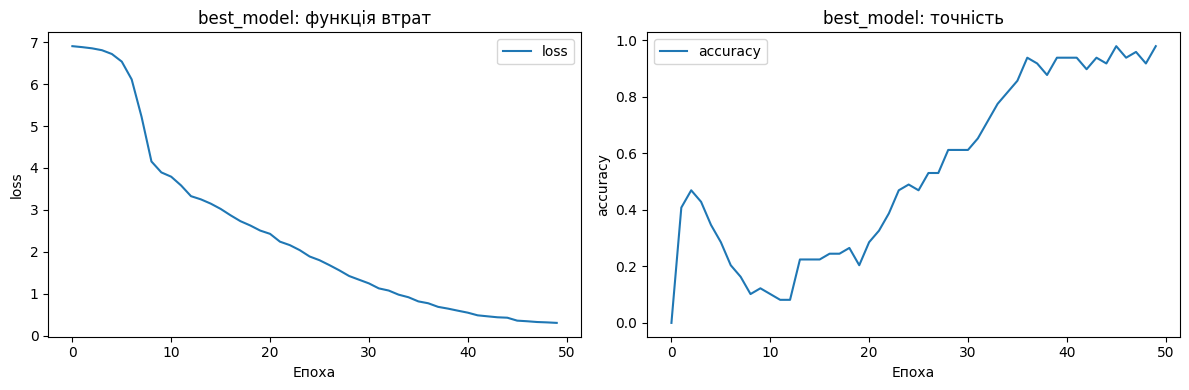

Модель      loss        accuracy    
model       1.8047      0.5510      
best_model  0.3025      0.9796      
model:      Думи мої думи лихо лихо лихо на на на чом чом вітер не не в винесли в не не в винесли в не
best_model: Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(best_history.history['loss'])
ax[0].set_title('best_model: функція втрат')
ax[0].set_xlabel('Епоха')
ax[0].set_ylabel('loss')
ax[0].legend(['loss'])

ax[1].plot(best_history.history['accuracy'])
ax[1].set_title('best_model: точність')
ax[1].set_xlabel('Епоха')
ax[1].set_ylabel('accuracy')
ax[1].legend(['accuracy'])

plt.tight_layout()
plt.show()

# Порівняння фінальних навчальних показників
print(f"{'Модель':<12}{'loss':<12}{'accuracy':<12}")
print(f"{'model':<12}{history.history['loss'][-1]:<12.4f}{history.history['accuracy'][-1]:<12.4f}")
print(f"{'best_model':<12}{best_history.history['loss'][-1]:<12.4f}{best_history.history['accuracy'][-1]:<12.4f}")

# buildPhrase з параметром моделі
def buildPhrase(texts, str_len=20, m=None):
    m = m if m is not None else model
    data = tokenizer.texts_to_sequences([texts])[0]
    if len(data) < inp_words:
        return f"Потрібно щонайменше {inp_words} відомих слова, знайдено {len(data)}"
    result = texts
    for _ in range(str_len):
        x = np.array(data[-inp_words:]).reshape(1, inp_words)
        idx = int(np.argmax(m.predict(x, verbose=0), axis=1)[0])
        data.append(idx)
        result += " " + tokenizer.index_word.get(idx, "")
    return result

print("model:     ", buildPhrase("Думи мої думи", 20, model))
print("best_model:", buildPhrase("Думи мої думи", 20, best_model))